# Field tracing applications: a laser diode collimator and fibre coupling

Notebook 109 (field tracing) introduced field tracing: the light is always carried as a
complex field on a grid, rays take it through the lenses (`ft.Trace`) and
wave optics takes it through free space and through the focus
(`ft.Propagate`). This notebook applies it to two everyday tasks of laser
optics, modelled on two application examples of the commercial field
tracing software VirtualLab Fusion (LightTrans):

1. **Collimating a laser diode.** An edge-emitting diode emits an
   elliptical, strongly diverging and *astigmatic* beam. How well does an
   aspheric lens collimate it, and what does the astigmatism do to the
   collimated beam and to a focus behind it?
2. **Coupling into a single-mode fibre.** A lens focuses a collimated laser
   beam onto the core of a fibre. How much of the power ends up in the
   guided mode, with a spherical lens and with an asphere?

Both questions need rays *and* waves. The lenses are thick, strongly
curved and aspheric, which is what ray tracing handles best. The answers,
though, are wave-optical quantities: the divergence and the beam quality
$M^2$ of a beam that is nearly diffraction limited, the size of a focal
spot of a few micrometres, the overlap of a field with a fibre mode. A ray
tracer would report a wavefront error and a spot diagram; a field tracer
reports what the next element in the system actually receives.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import fieldtrace as ft
from pyoptics import sketch
from pyoptics.raytrace import System, Surface, hyperbolic_lens

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "0.45"
t_start = time.time()

## Part 1: Collimating a laser diode

### The setup

The diode emits at 1064 nm from a facet only a few micrometres high and a
few wide. Diffraction from such a small aperture makes the beam diverge
fast: in our example the full angle at half maximum (FWHM) of the
far-field irradiance is 20° in $x$ and 10° in $y$. The two directions also
have their waists in different places: the beam in $y$ seems to come from
a point $\Delta = 11.6\ \mu\mathrm{m}$ in front of the point the beam in
$x$ comes from. This is the **astigmatism** of the diode (typical of gain
guided lasers, where the wavefronts in the junction plane are curved).

An aspheric lens of focal length $f_1 = 4$ mm and a numerical aperture of
about 0.6 collimates the beam. It is aligned on the waist in $x$, so the
beam in $x$ comes out perfectly collimated, while the beam in $y$ starts
a little closer to the lens than the focal point and comes out slightly
divergent. A second lens ($f_2 = 12$ mm) then focuses the collimated beam,
and images the two waists to two foci a distance
$\approx \Delta\,(f_2/f_1)^2 \approx 0.1$ mm apart (the longitudinal
magnification of an imaging system is the square of the lateral one).

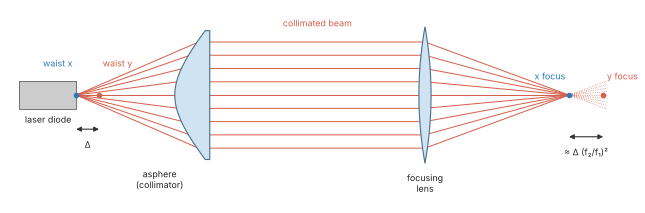

In [2]:
fig, ax = plt.subplots(figsize=(12, 3.2))
sketch.diode_collimator(ax)
plt.show()

### The source field

We describe the diode by its far field: a Gaussian distribution of
directions with the given FWHM angles, i.e. $1/e^2$ half angles
$\theta = \mathrm{FWHM}/\sqrt{2\ln 2}$, radiated from the waist in $x$ and,
in $y$, from a point $\Delta$ further on. One millimetre in front of the
$x$ waist the field is

$$E(x, y) = \exp\!\left[-\left(\frac{\arctan(x/z_x)}{\theta_x}\right)^2
 -\left(\frac{\arctan(y/z_y)}{\theta_y}\right)^2\right]
 \frac{z_x}{r}\, e^{i\psi(x, y)},
\qquad z_x = 1\ \mathrm{mm},\ z_y = z_x - \Delta,$$

with the exact spherical phase $\psi = k(r - z_x)$, $r = \sqrt{x^2 + y^2 +
z_x^2}$, plus the small extra curvature
$k y^2 (1/z_y - 1/z_x)/2$ of the $y$ part. At this plane the wavefront has
radii of only one millimetre, so its phase changes by hundreds of waves
over the window, and sampling it would take thousands of points per axis. We hand the quadratic part of it, $k x^2/(2 z_x) + k y^2/(2
z_y)$, to the field as the analytic phase (`alpha`, see notebook 109, field tracing) and
sample only the rest, which is gentle: 512 × 512 samples over 2 mm are
plenty.

1/e^2 half angles: 17.0° x 8.5°
analytic phase: alpha = (2953, 2987) rad/mm²
quadratic phase at the window edge: 470 waves; it alone would need 3759 samples per axis, the field has 512


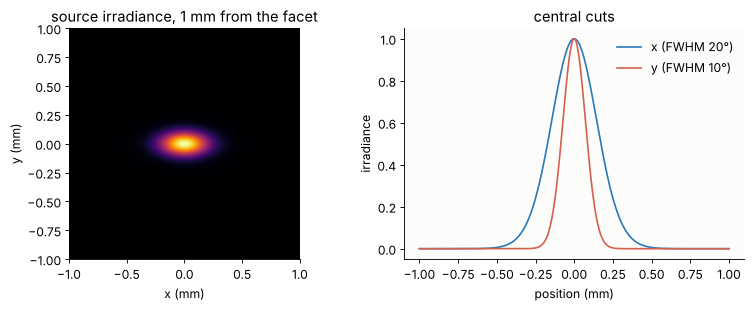

In [3]:
wl = 1.064e-3                                      # mm
k = 2*np.pi/wl
fwhm_x, fwhm_y = np.radians(20.0), np.radians(10.0)
th_x, th_y = fwhm_x/np.sqrt(2*np.log(2)), fwhm_y/np.sqrt(2*np.log(2))   # 1/e^2 half angles
delta = 11.6e-3                                    # astigmatic distance of the waists
z_src = 1.0                                        # source plane, 1 mm in front of the x waist


def diode(astigmatism, N=512, half=1.0):
    x = np.linspace(-half, half, N)
    X, Y = np.meshgrid(x, x)
    zx = z_src
    zy = z_src - (delta if astigmatism else 0.0)
    r = np.sqrt(X**2 + Y**2 + zx**2)
    psi = k*(r - zx) + k*Y**2/2*(1/zy - 1/zx)
    A = np.exp(-(np.arctan(X/zx)/th_x)**2 - (np.arctan(Y/zy)/th_y)**2)*zx/r
    alpha = (k/(2*zx), k/(2*zy))
    quad = alpha[0]*X**2 + alpha[1]*Y**2
    return ft.Field(A*np.exp(1j*(psi - quad)), x, x, wl, alpha=alpha)


src = diode(True)
print("1/e^2 half angles: {:.1f}° x {:.1f}°".format(np.degrees(th_x), np.degrees(th_y)))
print("analytic phase: alpha = ({:.0f}, {:.0f}) rad/mm²".format(*src.alpha))
half = src.x[-1]
print("quadratic phase at the window edge: {:.0f} waves; it alone would need {:.0f} samples per axis, "
      "the field has {}".format(src.alpha[0]*half**2/(2*np.pi), 2*half*2*src.alpha[0]*half/np.pi,
                                src.shape[-1]))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
I = src.irradiance()
ext = [src.x[0], src.x[-1], src.y[0], src.y[-1]]
ax[0].imshow(I/I.max(), extent=ext, origin="lower", cmap="inferno")
ax[0].set(xlabel="x (mm)", ylabel="y (mm)", title="source irradiance, 1 mm from the facet")
ax[1].plot(src.x, I[256]/I.max(), color=BLUE, label="x (FWHM 20°)")
ax[1].plot(src.y, I[:, 256]/I.max(), color=RED, label="y (FWHM 10°)")
ax[1].set(xlabel="position (mm)", ylabel="irradiance", title="central cuts")
ax[1].legend(frameon=False)
plt.tight_layout()
plt.show()

### The collimator

The collimator is a plano-convex asphere whose convex face, a hyperboloid
with conic constant $K = -n^2$ and vertex radius $R = (n - 1) f_1$, faces
the diode. Such a surface refracts all rays from its focal point exactly
parallel to the axis inside the glass (it is the mirror image of
`raytrace.hyperbolic_lens`, which focuses a collimated beam); the flat back
does not bend them. For a point source on the axis this lens is perfect,
at any aperture. Its clear aperture of 6.6 mm (NA ≈ 0.64) passes the beam
up to about 2.5 times its $1/e^2$ radius, so it hardly clips it.

`ft.Trace` takes the field through the lens with rays (one per grid
sample, with the Fresnel transmission at both surfaces) to a plane 5 mm
behind it.

In [4]:
n, f1 = 1.5, 4.0
R1, K1 = (n - 1)*f1, -n**2                         # hyperbolic face towards the diode
semi = 3.3
c1 = 1/R1
sag = c1*semi**2/(1 + np.sqrt(1 - (1 + K1)*c1**2*semi**2))
collimator = System([Surface(R=R1, conic=K1, thickness=sag + 1.0, n_after=n, semi_diameter=semi),
                     Surface(thickness=5.0, n_after=1.0, semi_diameter=semi)], 0, wl)
print("NA {:.2f}, centre thickness {:.2f} mm".format(np.sin(np.arctan(semi/f1)), sag + 1.0))

collimate = ft.Chain([ft.Trace(collimator, distance=f1 - z_src)])
t0 = time.time()
beams = {}
for astig in (False, True):
    res = collimate.run(diode(astig))
    beams[astig] = res.field
print(res.report())
print("{:.1f} s for both; transmitted power {:.3f} (Fresnel losses of the uncoated lens)".format(
    time.time() - t0, beams[True].power()/diode(True).power()))

NA 0.64, centre thickness 2.76 mm


  #  step                         method              error     samples pol.          ms  notes
  0  trace 2 surfaces             geometric (ray                512x512 scalar     328.2  5.2e-10 of the power in evanescent local waves: dropped; 8.7e-04 of the power vignetted or lost
0.7 s for both; transmitted power 0.934 (Fresnel losses of the uncoated lens)


### Two views of the collimated beam

A **ray tracer** judges the collimated beam by its wavefront: the optical
path difference across the beam, as peak-to-valley (P-V) and RMS in
waves, after removing piston and tilt. We evaluate it inside the $1/e^2$
region of the beam, weighted with the irradiance.

The **field** gives what matters to the user of the beam: how fast it
diverges and how close it is to an ideal Gaussian beam. Both come from
second moments. The width is $\sigma_x^2 = \langle (x - \bar x)^2 \rangle$
over the irradiance, the angular spread $\sigma_\theta^2$ the same moment
of the plane wave spectrum (the Fourier transform of the field, with
$\theta = k_x/k$). The divergence half angle is $2\sigma_\theta$ (the
$1/e^2$ angle for a Gaussian beam) and the beam quality factor is

$$M^2 = \frac{4\pi}{\lambda}\sqrt{\sigma_x^2\sigma_\theta^2 - \langle x\theta\rangle^2},$$

where the mixed moment $\langle x\theta\rangle$ removes the effect of a
curved wavefront (ISO 11146). $M^2 = 1$ for a perfect Gaussian beam and
larger for any other. Because second moments weight the edges heavily,
$M^2$ is sensitive to how the beam is truncated, which a field tracer
sees and a ray tracer does not.

In [5]:
def wavefront_error(f):
    # total phase in waves, piston and tilt removed (weighted fit) in the 1/e^2 region
    E = f.E()[0]
    I = np.abs(E)**2
    X, Y = np.meshgrid(f.x, f.y)
    W = (f.phase() + np.angle(f.amplitudes()[0]))/(2*np.pi)
    m = I > np.exp(-2)*I.max()
    G = np.c_[np.ones(m.sum()), X[m], Y[m]]
    s = np.sqrt(I[m])
    coef = np.linalg.lstsq(G*s[:, None], W[m]*s, rcond=None)[0]
    Wr = np.full(W.shape, np.nan)
    Wr[m] = W[m] - G@coef
    rms = np.sqrt(np.sum(I[m]*Wr[m]**2)/I[m].sum())
    return Wr, np.nanmax(Wr) - np.nanmin(Wr), rms


def beam_quality(f):
    E = f.E()[0]
    x, y = f.x, f.y
    X, Y = np.meshgrid(x, y)
    dx, dy = x[1] - x[0], y[1] - y[0]
    I = np.abs(E)**2
    P = I.sum()
    S = np.abs(np.fft.fftshift(np.fft.fft2(E)))**2           # plane wave spectrum
    kx = 2*np.pi*np.fft.fftshift(np.fft.fftfreq(len(x), dx))
    ky = 2*np.pi*np.fft.fftshift(np.fft.fftfreq(len(y), dy))
    KX, KY = np.meshgrid(kx, ky)
    out = {}
    for name, C, KC, axis, d in (("x", X, KX, 1, dx), ("y", Y, KY, 0, dy)):
        c0 = np.sum(C*I)/P
        s2 = np.sum((C - c0)**2*I)/P
        t0 = np.sum(KC*S)/S.sum()
        st2 = np.sum((KC - t0)**2*S)/S.sum()/k**2
        dE = np.gradient(E, d, axis=axis)
        cross = np.sum((C - c0)*np.imag(np.conj(E)*dE))/P/k  # <x theta>
        out["w" + name] = 2*np.sqrt(s2)
        out["div" + name] = np.degrees(2*np.sqrt(st2))
        out["M2" + name] = 4*np.pi/wl*np.sqrt(max(s2*st2 - cross**2, 0.0))
    return out


print("{:>18} | {:>9} {:>9} | {:>8} {:>8} | {:>9} {:>9} | {:>6} {:>6}".format(
    "", "P-V (λ)", "RMS (λ)", "w_x (mm)", "w_y (mm)", "div x (°)", "div y (°)", "M²x", "M²y"))
fronts = {}
for astig in (False, True):
    Wr, pv, rms = wavefront_error(beams[astig])
    fronts[astig] = Wr
    q = beam_quality(beams[astig])
    print("{:>18} | {:9.4f} {:9.4f} | {:8.3f} {:8.3f} | {:9.4f} {:9.4f} | {:6.3f} {:6.3f}".format(
        "with astigmatism" if astig else "no astigmatism", pv, rms, q["wx"], q["wy"],
        q["divx"], q["divy"], q["M2x"], q["M2y"]))

                   |   P-V (λ)   RMS (λ) | w_x (mm) w_y (mm) | div x (°) div y (°) |    M²x    M²y
    no astigmatism |    0.0000    0.0000 |    1.340    0.619 |    0.0170    0.0323 |  1.172  1.030
  with astigmatism |    0.1129    0.0230 |    1.340    0.620 |    0.0170    0.0396 |  1.174  1.032


Without astigmatism the asphere is perfect: the wavefront is flat to
numerical precision. Yet the beam is not an ideal Gaussian beam: $M^2_x
\approx 1.17$. The diode's far field is Gaussian in the *angle*, and the
hyperbolic face maps a ray leaving the source at the angle $\theta$ to the
height

$$h = \frac{(n - 1) f_1 \sin\theta}{n\cos\theta - 1},$$

which grows faster than $f_1\theta$: at the $1/e^2$ angle of 17° the
height is 13 % larger than $f_1\theta$. The wings of the collimated
profile are stretched, so it is no longer a Gaussian. In $x$, with the
larger divergence, the distortion is larger. A wavefront analysis cannot see this; the second
moments of the field do.

With astigmatism the wavefront in $y$ is curved: P-V about 0.1 λ, almost
all of it in $y$. The beam is still nearly diffraction limited, and $M^2$
does not change, because the curvature is the clean quadratic of a
slightly divergent beam (the mixed moment removes it). It does change the
divergence in $y$, by about 20 %. That is what limits how far the beam
can travel before it spreads. The beam in $y$ now diverges from a virtual
point at the distance $f_1^2/\Delta$ behind the lens (Newton's imaging
equation), which we can read off the fitted curvature of the traced field:

radius of curvature in y: 1.46 m (Newton, paraxial: f1²/Δ = 1.38 m)


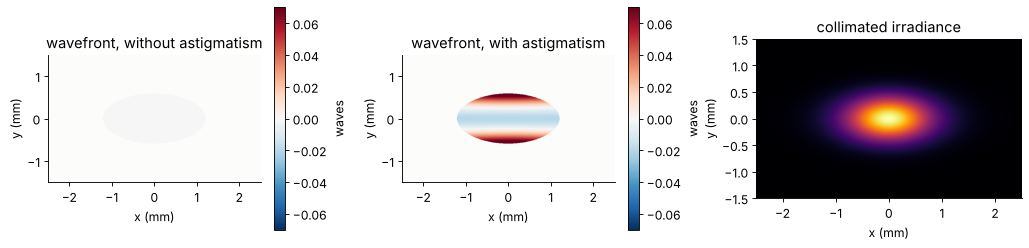

In [6]:
f = beams[True]
X, Y = np.meshgrid(f.x, f.y)
phi = f.phase() + np.angle(f.amplitudes()[0])
I = f.irradiance()
m = I > np.exp(-2)*I.max()
coef = np.linalg.lstsq(np.c_[np.ones(m.sum()), X[m]**2, Y[m]**2], phi[m], rcond=None)[0]
print("radius of curvature in y: {:.2f} m (Newton, paraxial: f1²/Δ = {:.2f} m)".format(
    k/(2*coef[2])/1e3, f1**2/delta/1e3))

fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
for a, astig in zip(ax[:2], (False, True)):
    Wr = fronts[astig]
    im = a.imshow(Wr, extent=[f.x[0], f.x[-1], f.y[0], f.y[-1]], origin="lower", cmap="RdBu_r",
                  vmin=-0.07, vmax=0.07)
    a.set(xlim=(-2.5, 2.5), ylim=(-1.5, 1.5), xlabel="x (mm)", ylabel="y (mm)",
          title="wavefront, " + ("with" if astig else "without") + " astigmatism")
    plt.colorbar(im, ax=a, label="waves", shrink=0.8)
I = beams[True].irradiance()
ax[2].imshow(I/I.max(), extent=[f.x[0], f.x[-1], f.y[0], f.y[-1]], origin="lower", cmap="inferno")
ax[2].set(xlim=(-2.5, 2.5), ylim=(-1.5, 1.5), xlabel="x (mm)", ylabel="y (mm)",
          title="collimated irradiance")
plt.tight_layout()
plt.show()

### Focusing the collimated beam

Behind the collimator a second asphere, a plano-convex hyperbolic lens of
$f_2 = 12$ mm (`raytrace.hyperbolic_lens`), focuses the beam. We trace
through it and hand over to wave optics 0.5 mm behind its back vertex
(`Chain.from_system(..., gap=0.5)`). From there `ft.Propagate` computes the
field in planes around the focus. Rays would put the whole focus of the
perfect lens into a single point; the waves give the real spot, a few
micrometres wide.

With the beam radii from the table above, the focusing cone has an NA
of about 0.11 in $x$ and half that in $y$, so the spot is elliptical, wider
in $y$. With astigmatism the focus in $y$ moves away from the lens, by
about $\Delta (f_2/f_1)^2 \approx 0.10$ mm.

In [7]:
f2 = 12.0
focuser = hyperbolic_lens(3.0, f2, n=n, wavelength=wl)
handover = ft.Chain.from_system(focuser, gap=0.5)[:1]
xd = np.linspace(-0.03, 0.03, 301)
dzs = np.linspace(-0.2, 0.3, 26)


def fwhm(profile, x):
    # full width at half maximum, linear interpolation of the two crossings
    p = profile/profile.max()
    i = np.where(p >= 0.5)[0]
    lo, hi = i[0], i[-1]
    xl = np.interp(0.5, [p[lo - 1], p[lo]], [x[lo - 1], x[lo]])
    xr = np.interp(0.5, [p[hi + 1], p[hi]], [x[hi + 1], x[hi]])
    return xr - xl


t0 = time.time()
scans = {}
for astig in (False, True):
    near = handover.run(beams[astig]).field
    cut_x, cut_y = [], []
    for dz in dzs:
        r = ft.Chain([ft.Propagate(f2 - 0.5 + dz), ft.Detector("d", x=xd, y=xd)]).run(near)
        I = r["d"].irradiance
        cut_x.append(I[150])
        cut_y.append(I[:, 150])
    scans[astig] = np.array(cut_x), np.array(cut_y)
print(r.report())
print("{} planes in {:.0f} s".format(2*len(dzs), time.time() - t0))

  #  step                         method              error     samples pol.          ms  notes
  0  propagate 11.8               spw               0.0e+00   1088x1194 scalar     998.8  
                                  candidates (error/effort): spw 0.0e+00/1279308, fresnel 4.0e-01/1279308, fresnel_ft 4.0e-01/524288, farfield 1.3e+00/262144, geometric inf/inf
  1  detector 'd'                 detector                    1088x1194 scalar     323.9  
52 planes in 68 s


  no astigmatism: at z = 0 FWHM x 3.5 µm, y 7.5 µm; narrowest y at z = +0 µm
     astigmatism: at z = 0 FWHM x 3.5 µm, y 9.6 µm; narrowest y at z = +80 µm


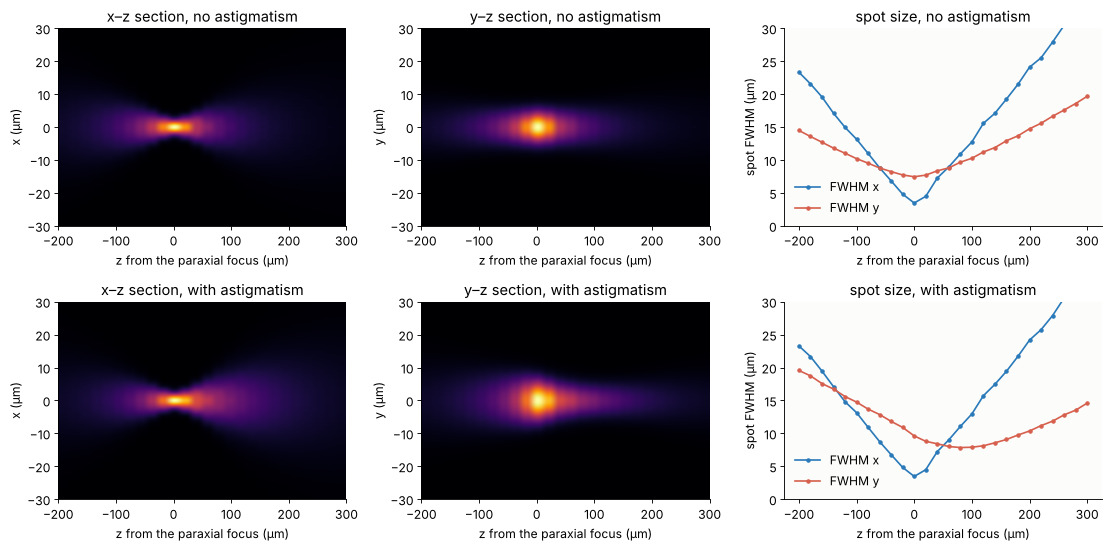

In [8]:
fig, ax = plt.subplots(2, 3, figsize=(14, 7), gridspec_kw={"width_ratios": [1, 1, 1.1]})
for row, astig in enumerate((False, True)):
    cx, cy = scans[astig]
    vmax = max(cx.max(), cy.max())
    for a, c, name in ((ax[row, 0], cx, "x"), (ax[row, 1], cy, "y")):
        a.imshow(c.T/vmax, extent=[dzs[0]*1e3, dzs[-1]*1e3, xd[0]*1e3, xd[-1]*1e3], aspect="auto",
                 origin="lower", cmap="inferno", vmax=1.0)
        a.set(xlabel="z from the paraxial focus (µm)", ylabel=name + " (µm)",
              title="{}–z section, {} astigmatism".format(name, "with" if astig else "no"))
    wx = [1e3*fwhm(p, xd) for p in cx]
    wy = [1e3*fwhm(p, xd) for p in cy]
    a = ax[row, 2]
    a.plot(dzs*1e3, wx, "o-", color=BLUE, ms=3, label="FWHM x")
    a.plot(dzs*1e3, wy, "o-", color=RED, ms=3, label="FWHM y")
    a.set(xlabel="z from the paraxial focus (µm)", ylabel="spot FWHM (µm)", ylim=(0, 30),
          title="spot size, {} astigmatism".format("with" if astig else "no"))
    a.legend(frameon=False)
    i0 = np.argmin(np.abs(dzs))
    print("{:>16}: at z = 0 FWHM x {:.1f} µm, y {:.1f} µm; narrowest y at z = {:+.0f} µm".format(
        "astigmatism" if astig else "no astigmatism", wx[i0], wy[i0], 1e3*dzs[np.argmin(wy)]))
plt.tight_layout()
plt.show()

Without astigmatism both directions focus in the same plane; the spot is
about twice as wide in $y$, the direction of the narrower collimated beam.
With astigmatism the $x$ focus is unchanged, while the narrowest spot in
$y$ moves 80 to 100 µm away from the lens, as Newton's equation predicts
(the minimum of the $y$ width is shallow and the scan has 20 µm steps). In the
$x$ focus the spot in $y$ is now larger, and no plane has a round, tight
spot. The diode's 12 µm are magnified to a tenth of a millimetre.

This is the same trend as in the VirtualLab example: the astigmatism of
the diode is invisible in $M^2$, but shows up as a larger divergence in
one direction and as two separated line-like foci behind a focusing lens.
In a real system one would correct it with a weak cylindrical lens, which
could be added to the chain as one more `ft.Trace` or `ft.ThinLens(f,
axis="y")`.

## Part 2: Coupling a laser beam into a single-mode fibre

### The setup

A collimated Gaussian beam at 780 nm with a diameter of 660 µm
($1/e^2$ radius $w = 0.33$ mm) is focused into a single-mode fibre with a
mode field diameter of 3 µm. The lens has a focal length of $f = 2$ mm, so
an ideal lens makes a focus of waist

$$w_0 = \frac{\lambda f}{\pi w} = 1.50\ \mu\mathrm{m},$$

which matches the fibre mode exactly. The question is how close real
lenses get, and where the fibre has to be. We compare two plano-convex
lenses of the same focal length:

* a **spherical** lens, curved side towards the beam (the better of its
  two orientations), radius $R = (n - 1) f$, and
* an **asphere**, a hyperbolic lens that is free of spherical aberration.

The fibre mode of a step index fibre is close to a Gaussian, so we model
it as one: $M(x, y) = \exp(-r^2/w_f^2)$ with $w_f = 1.5$ µm.

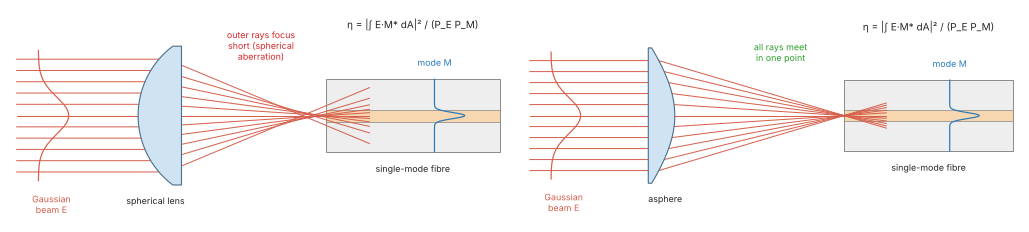

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.2))
sketch.fibre_coupling(ax[0], lens="spherical")
sketch.fibre_coupling(ax[1], lens="aspheric")
plt.tight_layout()
plt.show()

### The coupling efficiency

The fraction of the power of a field $E$ that couples into a mode $M$ is
the squared overlap integral

$$\eta = \frac{\left|\int E \cdot M^* \,\mathrm{d}A\right|^2}
              {\int |E|^2 \,\mathrm{d}A \int |M|^2 \,\mathrm{d}A}.$$

It is 1 only if the field has exactly the shape *and the phase* of the
mode; a field that is a little too large or too small, shifted, tilted
or with a curved or aberrated wavefront couples less. That makes it a
quantity that needs the full complex field at the fibre face, which is
what a field tracer delivers. In `pyoptics.fieldtrace` it is
`Field.overlap(mode)`, and a detector evaluates it when asked for
`"coupling"`:

```python
ft.Detector("fibre", ("coupling",), x=xm, y=xm, mode=fibre_mode)
```

The mode is sampled on its own small grid around the core, and the field
is resampled onto it. Power outside that grid counts as lost.

First a check against two textbook cases: two Gaussian beams with waists
$w_1, w_2$ couple with $\eta = \left(2 w_1 w_2/(w_1^2 + w_2^2)\right)^2$, and
a lateral offset $d$ of matched beams gives $\eta = e^{-d^2/w^2}$.

In [10]:
wl2 = 0.78e-3
w_beam, f_lens, w_fibre = 0.33, 2.0, 1.5e-3
xm = np.linspace(-8e-3, 8e-3, 161)                   # the fibre grid, ±8 µm
mode = ft.gaussian(w_fibre, wl2, xm, xm)
print("ideal focal waist: {:.3f} µm".format(1e3*wl2*f_lens/(np.pi*w_beam)))

for w2 in (1.2e-3, 2.0e-3):
    print("waists 1.5/{:.1f} µm: eta = {:.4f} (analytic {:.4f})".format(
        1e3*w2, ft.gaussian(w2, wl2, xm, xm).overlap(mode), (2*w_fibre*w2/(w_fibre**2 + w2**2))**2))
XM, YM = np.meshgrid(xm, xm)
d = 1.0e-3
shifted = ft.from_array(np.exp(-((XM - d)**2 + YM**2)/w_fibre**2), xm, xm, wl2)
print("offset 1 µm: eta = {:.4f} (analytic {:.4f})".format(shifted.overlap(mode),
                                                          np.exp(-d**2/w_fibre**2)))

ideal focal waist: 1.505 µm
waists 1.5/1.2 µm: eta = 0.9518 (analytic 0.9518)
waists 1.5/2.0 µm: eta = 0.9216 (analytic 0.9216)
offset 1 µm: eta = 0.6412 (analytic 0.6412)


### The two lenses

Both lenses are made of glass with $n = 1.511$ (N-BK7 at 780 nm). The
spherical lens is 1 mm thick with $R = 1.02$ mm; its paraxial back focal
length is $f - t/n$. The asphere is `hyperbolic_lens(1.0, 2.0)`, flat side
towards the beam. Both have a clear radius of 1 mm, three times the beam
radius, so the aperture does not cut the beam.

The chain traces the beam through each lens to a plane 0.3 mm behind it
and propagates from there to the fibre. We move the fibre along the axis
and record the coupling efficiency.

In [11]:
n2 = 1.511
R_s, t_s = (n2 - 1)*f_lens, 1.0
spherical = System([Surface(R=R_s, thickness=t_s, n_after=n2, semi_diameter=1.0),
                    Surface(thickness=f_lens - t_s/n2, n_after=1.0, semi_diameter=1.0)], 0, wl2)
aspheric = hyperbolic_lens(1.0, f_lens, n=n2, wavelength=wl2, edge=0.3)
x_src = np.linspace(-1.1, 1.1, 256)
beam = ft.gaussian(w_beam, wl2, x_src, x_src)

lenses = {"spherical": spherical, "aspheric": aspheric}
gap = 0.3
scan = {"spherical": np.linspace(-0.08, 0.02, 41), "aspheric": np.linspace(-0.015, 0.015, 31)}
coupling, best, near_fields = {}, {}, {}
t0 = time.time()
for name, system in lenses.items():
    near = ft.Chain.from_system(system, gap=gap)[:1].run(beam).field
    near_fields[name] = near
    rest = system.surfaces[-1].thickness - gap       # to the paraxial focus
    eta = []
    for dz in scan[name]:
        r = ft.Chain([ft.Propagate(rest + dz),
                      ft.Detector("fibre", ("coupling",), x=xm, y=xm, mode=mode)]).run(near)
        eta.append(r["fibre"].coupling)
    coupling[name] = np.array(eta)
    i = np.argmax(eta)
    best[name] = scan[name][i]
    print("{:>9}: transmitted power {:.3f}; best coupling {:.2%} with the fibre {:+.1f} µm from the "
          "paraxial focus, working distance {:.4f} mm".format(
              name, near.power()/beam.power(), eta[i], 1e3*scan[name][i],
              system.surfaces[-1].thickness + scan[name][i]))
print("{:.0f} s".format(time.time() - t0))

spherical: transmitted power 0.919; best coupling 72.27% with the fibre -30.0 µm from the paraxial focus, working distance 1.3082 mm


 aspheric: transmitted power 0.918; best coupling 99.65% with the fibre +0.0 µm from the paraxial focus, working distance 2.0000 mm
26 s


The transmitted power, about 92 %, is the Fresnel reflection loss of
4 % at each of the two uncoated surfaces; an AR coating would remove it
(`ft.Trace(..., coatings=...)`). The coupling efficiency counts only the
light that arrives, and it is where the two lenses differ:

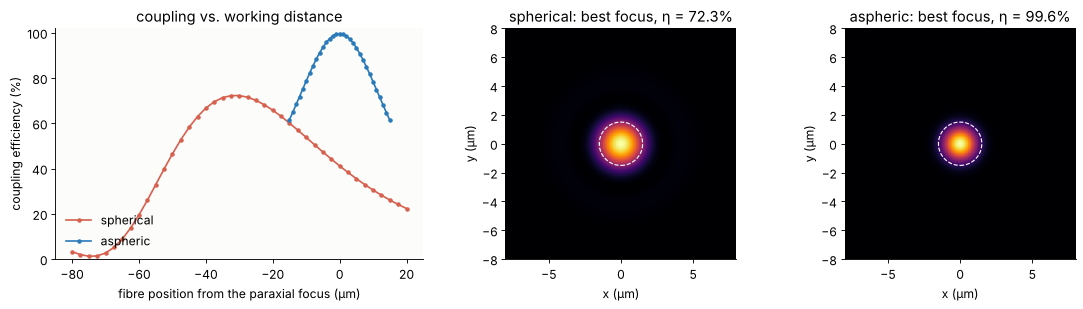

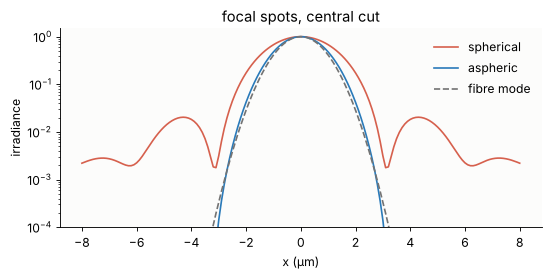

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4), gridspec_kw={"width_ratios": [1.3, 1, 1]})
for name, color in (("spherical", RED), ("aspheric", BLUE)):
    ax[0].plot(1e3*scan[name], 100*coupling[name], "o-", ms=3, color=color, label=name)
ax[0].set(xlabel="fibre position from the paraxial focus (µm)", ylabel="coupling efficiency (%)",
          ylim=(0, 102), title="coupling vs. working distance")
ax[0].legend(frameon=False, loc="lower left")
for a, name in zip(ax[1:], ("spherical", "aspheric")):
    rest = lenses[name].surfaces[-1].thickness - gap
    r = ft.Chain([ft.Propagate(rest + best[name]), ft.Detector("spot", x=xm, y=xm)]).run(near_fields[name])
    I = r["spot"].irradiance
    a.imshow(I/I.max(), extent=[1e3*xm[0], 1e3*xm[-1]]*2, origin="lower", cmap="inferno")
    a.contour(1e3*xm, 1e3*xm, np.abs(mode.E()[0])**2, levels=[np.exp(-2)], colors="w",
              linestyles="--", linewidths=1)
    a.set(xlabel="x (µm)", ylabel="y (µm)",
          title="{}: best focus, η = {:.1%}".format(name, coupling[name].max()))
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 3.6))
for name, color in (("spherical", RED), ("aspheric", BLUE)):
    rest = lenses[name].surfaces[-1].thickness - gap
    r = ft.Chain([ft.Propagate(rest + best[name]), ft.Detector("spot", x=xm, y=xm)]).run(near_fields[name])
    I = r["spot"].irradiance[80]
    ax.semilogy(1e3*xm, I/I.max(), color=color, label=name)
ax.semilogy(1e3*xm, np.exp(-2*xm**2/w_fibre**2), "--", color=GREY, label="fibre mode")
ax.set(xlabel="x (µm)", ylabel="irradiance", ylim=(1e-4, 1.5), title="focal spots, central cut")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

The asphere makes a focus that is almost the fibre mode itself: the
coupling efficiency is 99.6 %, at the paraxial focus. The small rest is no
aberration: the focusing cone is not quite paraxial, and the spot is a
few percent wider than $\lambda f/(\pi w)$ (a mode of 1.55 µm would take
99.8 %). The spherical lens has spherical
aberration: the outer parts of the beam focus closer to the lens. The best
position for the fibre moves about 30 µm towards the lens, and even there
the spot has a ring of light around a central core that does not match
the mode, and only about 70 % couple. The coupling also falls off much
faster with the fibre position; aligning a fibre behind such a lens is
harder. (Notebook 116 (fibre modes) computes such modes and their mode field diameters
for real fibre profiles, and the splice loss of a lateral offset.)

The VirtualLab example (with the actual catalogue lenses, whose
prescriptions we do not have) reports 88 % for the spherical lens and
99.98 % for the asphere. Both agree that the asphere is essentially
perfect; the number for the spherical lens depends on the lens: its glass, thickness, shape
and orientation. This chain makes it easy to try those: change the
`System` and run again.

### Alignment tolerance

Finally, the lateral tolerance: with the asphere at its best focus we
shift the fibre sideways. For a perfect focus the efficiency follows
$e^{-d^2/w_f^2}$, which drops to 1/e at an offset of the mode field radius,
1.5 µm. To shift the fibre we shift the mode on its grid.

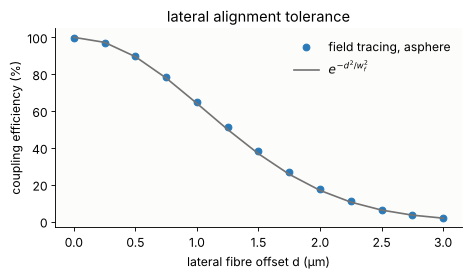

1 dB loss (79 %) at an offset of 0.72 µm


In [13]:
rest = aspheric.surfaces[-1].thickness - gap
spot = ft.Chain([ft.Propagate(rest + best["aspheric"])]).run(near_fields["aspheric"]).field
offsets = np.linspace(0, 3e-3, 13)
eta_off = [spot.overlap(ft.from_array(np.exp(-((XM - d)**2 + YM**2)/w_fibre**2), xm, xm, wl2))
           for d in offsets]
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(1e3*offsets, 100*np.array(eta_off), "o", color=BLUE, label="field tracing, asphere")
ax.plot(1e3*offsets, 100*np.exp(-offsets**2/w_fibre**2), color=GREY, label=r"$e^{-d^2/w_f^2}$")
ax.set(xlabel="lateral fibre offset d (µm)", ylabel="coupling efficiency (%)",
       title="lateral alignment tolerance")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()
print("1 dB loss (79 %) at an offset of {:.2f} µm".format(1e3*w_fibre*np.sqrt(-np.log(10**-0.1))))

## Summary

* **Laser diode collimator.** Tracing the diode field through an aspheric
  collimator shows that a perfect lens (flat wavefront) still delivers a
  beam with $M^2 \approx 1.17$, because the angular Gaussian far field of
  the diode is mapped to a non-Gaussian profile. The astigmatism of the
  diode does not change $M^2$, but adds about 0.1 λ of wavefront error,
  increases the divergence in one direction by about 20 % and separates
  the foci behind a focusing lens by $\Delta (f_2/f_1)^2$.
* **Fibre coupling.** The coupling efficiency is the overlap of the
  focused field with the fibre mode, `Field.overlap()` or a detector with
  `"coupling"`. The asphere couples 99.6 %, a spherical lens of
  the same focal length about 70 % at a working distance shorter by 30 µm.

In both cases the lenses are handled by rays, the focus and the coupling
by waves, with no need to pick grids by hand: the same split as in
notebook 109 (field tracing).

Reference: F. Wyrowski and M. Kuhn, "Introduction to field tracing",
J. Mod. Opt. 58, 449–466 (2011). The two setups follow the LightTrans
application examples "Laser diode collimation" and "Fiber coupling
efficiency" for VirtualLab Fusion.

In [14]:
print("total run time: {:.0f} s".format(time.time() - t_start))

total run time: 100 s
